## Câu 1. Đọc dữ liệu vào chương trình

In [1]:
import pandas as pd

print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 1")

# Đọc dữ liệu bán lẻ trong thư mục data
df = pd.read_excel("data/Online Retail.xlsx")

print("\nKích thước dữ liệu ban đầu")
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

print("\nNăm dòng dữ liệu đầu tiên")
print(df.head().to_string(index=False))

print("\nThông tin các thuộc tính")
df.info()

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 1

Kích thước dữ liệu ban đầu
Số dòng: 541909
Số cột: 8

Năm dòng dữ liệu đầu tiên
InvoiceNo StockCode                         Description  Quantity         InvoiceDate  UnitPrice  CustomerID        Country
   536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6 2010-12-01 08:26:00       2.55     17850.0 United Kingdom
   536365     71053                 WHITE METAL LANTERN         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom
   536365    84406B      CREAM CUPID HEARTS COAT HANGER         8 2010-12-01 08:26:00       2.75     17850.0 United Kingdom
   536365    84029G KNITTED UNION FLAG HOT WATER BOTTLE         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom
   536365    84029E      RED WOOLLY HOTTIE WHITE HEART.         6 2010-12-01 08:26:00       3.39     17850.0 United Kingdom

Thông tin các thuộc tính
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns 

## Câu 2. Xử lý Description và InvoiceNo

In [2]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 2")

du_lieu_cau2 = df.copy()

du_lieu_cau2["Description"] = du_lieu_cau2["Description"].str.strip()

so_dong_truoc = len(du_lieu_cau2)
du_lieu_cau2 = du_lieu_cau2.dropna(subset=["InvoiceNo"]).copy()

du_lieu_cau2["InvoiceNo"] = du_lieu_cau2["InvoiceNo"].astype("string")

print("\nSố dòng ban đầu:", so_dong_truoc)
print("Số dòng bị xóa:", so_dong_truoc - len(du_lieu_cau2))
print("Số dòng còn lại:", len(du_lieu_cau2))
print("Kiểu dữ liệu của InvoiceNo:", du_lieu_cau2["InvoiceNo"].dtype)
print("\nMười dòng sau xử lý")
print(du_lieu_cau2[["InvoiceNo", "Description", "Quantity"]].head(10).to_string(index=False))

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 2

Số dòng ban đầu: 541909
Số dòng bị xóa: 0
Số dòng còn lại: 541909
Kiểu dữ liệu của InvoiceNo: string

Mười dòng sau xử lý
InvoiceNo                         Description  Quantity
   536365  WHITE HANGING HEART T-LIGHT HOLDER         6
   536365                 WHITE METAL LANTERN         6
   536365      CREAM CUPID HEARTS COAT HANGER         8
   536365 KNITTED UNION FLAG HOT WATER BOTTLE         6
   536365      RED WOOLLY HOTTIE WHITE HEART.         6
   536365        SET 7 BABUSHKA NESTING BOXES         2
   536365   GLASS STAR FROSTED T-LIGHT HOLDER         6
   536366              HAND WARMER UNION JACK         6
   536366           HAND WARMER RED POLKA DOT         6
   536367       ASSORTED COLOUR BIRD ORNAMENT        32


## Câu 3. Xóa hóa đơn tín dụng

In [3]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 3")

la_hoa_don_tin_dung = du_lieu_cau2["InvoiceNo"].str.contains("C", na=False)

print("\nMột số hóa đơn tín dụng")
print(du_lieu_cau2.loc[la_hoa_don_tin_dung, ["InvoiceNo", "Description", "Quantity"]].head().to_string(index=False))

du_lieu_cau3 = du_lieu_cau2.loc[~la_hoa_don_tin_dung].copy()

print("\nSố dòng hóa đơn tín dụng đã loại:", int(la_hoa_don_tin_dung.sum()))
print("Số dòng còn lại:", len(du_lieu_cau3))
print("Số dòng có mã hóa đơn chứa C sau xử lý:", int(du_lieu_cau3["InvoiceNo"].str.contains("C", na=False).sum()))

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 3

Một số hóa đơn tín dụng
InvoiceNo                     Description  Quantity
  C536379                        Discount        -1
  C536383 SET OF 3 COLOURED  FLYING DUCKS        -1
  C536391   PLASTERS IN TIN CIRCUS PARADE       -12
  C536391 PACK OF 12 PINK PAISLEY TISSUES       -24
  C536391 PACK OF 12 BLUE PAISLEY TISSUES       -24

Số dòng hóa đơn tín dụng đã loại: 9288
Số dòng còn lại: 532621
Số dòng có mã hóa đơn chứa C sau xử lý: 0


## Câu 4. Thống kê số dòng dữ liệu theo quốc gia

In [4]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 4")

thong_ke_quoc_gia = du_lieu_cau3["Country"].value_counts(dropna=False)

print("\nSố dòng dữ liệu theo từng quốc gia")
print(thong_ke_quoc_gia.to_string())

print("\nSố dòng giao dịch của Germany:", int((du_lieu_cau3["Country"] == "Germany").sum()))
print("Tổng số dòng đã thống kê:", int(thong_ke_quoc_gia.sum()))

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 4

Số dòng dữ liệu theo từng quốc gia
Country
United Kingdom          487622
Germany                   9042
France                    8408
EIRE                      7894
Spain                     2485
Netherlands               2363
Belgium                   2031
Switzerland               1967
Portugal                  1501
Australia                 1185
Norway                    1072
Italy                      758
Channel Islands            748
Finland                    685
Cyprus                     614
Sweden                     451
Unspecified                446
Austria                    398
Denmark                    380
Poland                     330
Japan                      321
Israel                     295
Hong Kong                  284
Singapore                  222
Iceland                    182
USA                        179
Canada                     151
Greece                     145
Malta              

## Câu 5. Lọc giao dịch Germany và gom nhóm theo hóa đơn, mặt hàng

In [13]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 5")

du_lieu_duc = du_lieu_cau3.loc[du_lieu_cau3["Country"] == "Germany"].copy()

du_lieu_gom_nhom = (
    du_lieu_duc
    .groupby(["InvoiceNo", "Description"], as_index=False)["Quantity"]
    .sum()
)

print("\nSố dòng giao dịch của Germany:", len(du_lieu_duc))
print("Số hóa đơn khác nhau:", du_lieu_duc["InvoiceNo"].nunique())
print("Số dòng sau khi gom nhóm:", len(du_lieu_gom_nhom))

print("\nMười dòng kết quả gom nhóm")
print(du_lieu_gom_nhom.head(10).to_string(index=False))

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 5

Số dòng giao dịch của Germany: 9042
Số hóa đơn khác nhau: 457
Số dòng sau khi gom nhóm: 9015

Mười dòng kết quả gom nhóm
InvoiceNo                         Description  Quantity
   536527          3 HOOK HANGER MAGIC GARDEN        12
   536527       5 HOOK HANGER MAGIC TOADSTOOL        12
   536527   5 HOOK HANGER RED MAGIC TOADSTOOL        12
   536527 ASSORTED COLOUR LIZARD SUCTION HOOK        24
   536527        CHILDREN'S CIRCUS PARADE MUG        12
   536527        HOMEMADE JAM SCENTED CANDLES        12
   536527           HOT WATER BOTTLE BABUSHKA         4
   536527                      JUMBO BAG OWLS        10
   536527          JUMBO BAG WOODLAND ANIMALS        10
   536527  MULTI COLOUR SILVER T-LIGHT HOLDER        12


## Câu 6. Chuyển dữ liệu sang dạng hot encoding

In [14]:
from scipy.sparse import coo_matrix

print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 6")

danh_sach_hoa_don = pd.Index(du_lieu_gom_nhom["InvoiceNo"].unique())
danh_sach_mat_hang = pd.Index(du_lieu_gom_nhom["Description"].unique())

vi_tri_hoa_don = pd.Categorical(
    du_lieu_gom_nhom["InvoiceNo"], categories=danh_sach_hoa_don
).codes
vi_tri_mat_hang = pd.Categorical(
    du_lieu_gom_nhom["Description"], categories=danh_sach_mat_hang
).codes

ma_tran_gio_hang = coo_matrix(
    (du_lieu_gom_nhom["Quantity"].to_numpy(), (vi_tri_hoa_don, vi_tri_mat_hang)),
    shape=(len(danh_sach_hoa_don), len(danh_sach_mat_hang))
).tocsr()

gio_hang_duc = pd.DataFrame.sparse.from_spmatrix(
    ma_tran_gio_hang,
    index=danh_sach_hoa_don,
    columns=danh_sach_mat_hang
)
gio_hang_duc.index.name = "InvoiceNo"

print("\nKích thước bảng giỏ hàng tại Germany")
print("Số hóa đơn:", gio_hang_duc.shape[0])
print("Số mặt hàng:", gio_hang_duc.shape[1])

print("\nMẫu bảng hot encoding")
mau_gio_hang = gio_hang_duc.iloc[:5, :5].copy()
mau_gio_hang.columns = [str(ten)[:18] for ten in mau_gio_hang.columns]
print(mau_gio_hang.to_string())
print("\nCác giá trị trong bảng là số lượng mua, chưa chuyển về 0 và 1")

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 6

Kích thước bảng giỏ hàng tại Germany
Số hóa đơn: 457
Số mặt hàng: 1695

Mẫu bảng hot encoding
           3 HOOK HANGER MAGI  5 HOOK HANGER MAGI  5 HOOK HANGER RED   ASSORTED COLOUR LI  CHILDREN'S CIRCUS 
InvoiceNo                                                                                                    
536527                     12                  12                  12                  24                  12
536840                      0                   0                   0                   0                   0
536861                      0                   0                   0                   0                   0
536967                      0                   0                   0                   0                   0
536983                      0                   0                   0                   0                   0

Các giá trị trong bảng là số lượng mua, chưa chuyển về 0 và 1


## Câu 7. Chuyển từ hot encoding sang one-hot encoding

In [15]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 7")

one_hot_duc = gio_hang_duc.gt(0)

print("\nKích thước dữ liệu one-hot encoding")
print("Số hóa đơn:", one_hot_duc.shape[0])
print("Số mặt hàng:", one_hot_duc.shape[1])
print("\nNăm dòng và năm mặt hàng đầu tiên")
mau_one_hot = one_hot_duc.iloc[:5, :5].astype(int).copy()
mau_one_hot.columns = [str(ten)[:18] for ten in mau_one_hot.columns]
print(mau_one_hot.to_string())

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 7

Kích thước dữ liệu one-hot encoding
Số hóa đơn: 457
Số mặt hàng: 1695

Năm dòng và năm mặt hàng đầu tiên
           3 HOOK HANGER MAGI  5 HOOK HANGER MAGI  5 HOOK HANGER RED   ASSORTED COLOUR LI  CHILDREN'S CIRCUS 
InvoiceNo                                                                                                    
536527                      1                   1                   1                   1                   1
536840                      0                   0                   0                   0                   0
536861                      0                   0                   0                   0                   0
536967                      0                   0                   0                   0                   0
536983                      0                   0                   0                   0                   0


## Câu 8. Xóa thuộc tính POSTAGE

In [8]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 8")

print("\nSố mặt hàng trước khi xử lý:", one_hot_duc.shape[1])
one_hot_san_pham_duc = one_hot_duc.drop(columns=["POSTAGE"], errors="ignore")
print("Số mặt hàng sau khi xử lý:", one_hot_san_pham_duc.shape[1])
print("Số hóa đơn còn lại:", one_hot_san_pham_duc.shape[0])
print("Cột POSTAGE còn tồn tại:", "POSTAGE" in one_hot_san_pham_duc.columns)

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 8

Số mặt hàng trước khi xử lý: 1695
Số mặt hàng sau khi xử lý: 1694
Số hóa đơn còn lại: 457
Cột POSTAGE còn tồn tại: False


## Câu 9. Tìm tập phổ biến bằng Apriori với min_sup = 5%

In [16]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 9")

from mlxtend.frequent_patterns import apriori

thoi_gian_bat_dau = __import__("time").perf_counter()
tap_pho_bien_apriori_duc = apriori(
    one_hot_san_pham_duc,
    min_support=0.05,
    use_colnames=True
)
thoi_gian_apriori = __import__("time").perf_counter() - thoi_gian_bat_dau

tap_pho_bien_apriori_duc = tap_pho_bien_apriori_duc.sort_values(
    "support", ascending=False
).reset_index(drop=True)

print("\nSố tập phổ biến tìm được:", len(tap_pho_bien_apriori_duc))
print("Thời gian chạy Apriori (giây):", round(thoi_gian_apriori, 4))
print("\nCác tập phổ biến tìm được")
print(tap_pho_bien_apriori_duc.to_string(index=False))

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 9

Số tập phổ biến tìm được: 59
Thời gian chạy Apriori (giây): 0.0324

Các tập phổ biến tìm được
 support                                                                           itemsets
0.245077                                    frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})
0.157549                                     frozenset({ROUND SNACK BOXES SET OF 4 FRUITS})
0.137856                                              frozenset({REGENCY CAKESTAND 3 TIER})
0.137856                                      frozenset({PLASTERS IN TIN WOODLAND ANIMALS})
0.131291 frozenset({ROUND SNACK BOXES SET OF4 WOODLAND, ROUND SNACK BOXES SET OF 4 FRUITS})
0.126915                                                frozenset({WOODLAND CHARLOTTE BAG})
0.115974                                         frozenset({PLASTERS IN TIN CIRCUS PARADE})
0.107221                                              frozenset({PLASTERS IN TIN SPACEBOY})
0.102845

## Câu 10. Tạo luật kết hợp với min_conf = 50%

In [17]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 10")

from mlxtend.frequent_patterns import association_rules

luat_apriori_duc = association_rules(
    tap_pho_bien_apriori_duc,
    metric="confidence",
    min_threshold=0.5,
    num_itemsets=len(one_hot_san_pham_duc)
)

luat_apriori_duc = luat_apriori_duc.sort_values(
    ["confidence", "support"], ascending=False
).reset_index(drop=True)

cot_luat = ["antecedents", "consequents", "support", "confidence", "lift"]
print("\nSố luật kết hợp đạt yêu cầu:", len(luat_apriori_duc))
print("\nCác luật kết hợp tìm được")
print(luat_apriori_duc[cot_luat].to_string(index=False))

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 10

Số luật kết hợp đạt yêu cầu: 8

Các luật kết hợp tìm được
                                    antecedents                                     consequents  support  confidence     lift
       frozenset({RED RETROSPOT CHARLOTTE BAG})             frozenset({WOODLAND CHARLOTTE BAG}) 0.059081    0.843750 6.648168
 frozenset({ROUND SNACK BOXES SET OF 4 FRUITS}) frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}) 0.131291    0.833333 3.400298
                frozenset({SPACEBOY LUNCH BOX}) frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}) 0.070022    0.680851 2.778116
     frozenset({PLASTERS IN TIN CIRCUS PARADE})   frozenset({PLASTERS IN TIN WOODLAND ANIMALS}) 0.067834    0.584906 4.242887
          frozenset({PLASTERS IN TIN SPACEBOY})   frozenset({PLASTERS IN TIN WOODLAND ANIMALS}) 0.061269    0.571429 4.145125
  frozenset({PLASTERS IN TIN WOODLAND ANIMALS}) frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}) 0.074398    0.53968

## Câu 11. Vẽ biểu đồ phân tán Support và Confidence

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 11


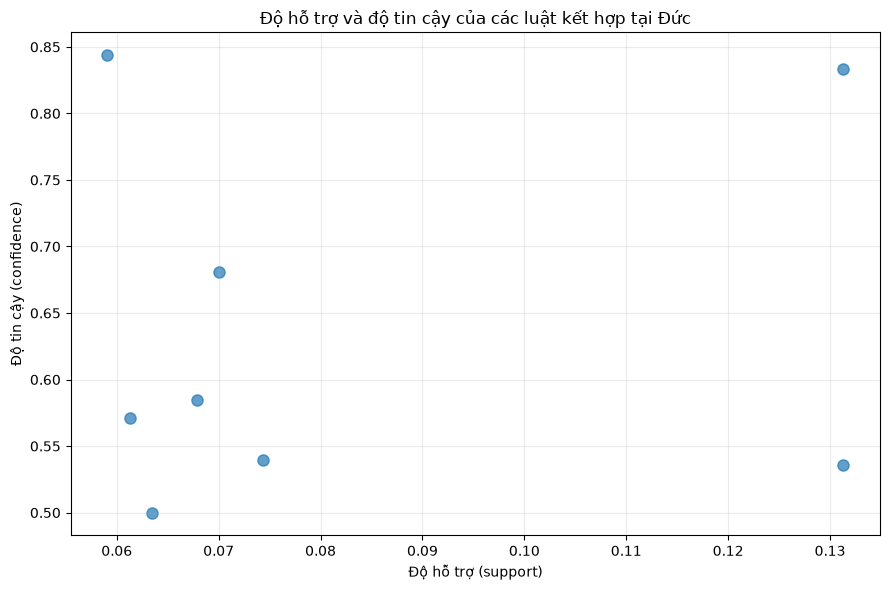


Số luật được biểu diễn: 8


In [18]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 11")

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))
plt.scatter(
    luat_apriori_duc["support"],
    luat_apriori_duc["confidence"],
    s=65,
    alpha=0.7
)
plt.xlabel("Độ hỗ trợ (support)")
plt.ylabel("Độ tin cậy (confidence)")
plt.title("Độ hỗ trợ và độ tin cậy của các luật kết hợp tại Đức")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("\nSố luật được biểu diễn:", len(luat_apriori_duc))

## Câu 12. FP-Growth với min_sup = 5%, min_conf = 50% và so sánh Apriori

In [19]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Phần 2, Bài 5a, Câu 12")

from mlxtend.frequent_patterns import fpgrowth
import time

thoi_gian_bat_dau = time.perf_counter()
tap_pho_bien_fp_duc = fpgrowth(
    one_hot_san_pham_duc,
    min_support=0.05,
    use_colnames=True
)
thoi_gian_fp = time.perf_counter() - thoi_gian_bat_dau

tap_pho_bien_fp_duc = tap_pho_bien_fp_duc.sort_values(
    "support", ascending=False
).reset_index(drop=True)

luat_fp_duc = association_rules(
    tap_pho_bien_fp_duc,
    metric="confidence",
    min_threshold=0.5,
    num_itemsets=len(one_hot_san_pham_duc)
)
luat_fp_duc = luat_fp_duc.sort_values(
    ["confidence", "support"], ascending=False
).reset_index(drop=True)

print("\nCác tập phổ biến của FP-Growth")
print(tap_pho_bien_fp_duc.to_string(index=False))
print("\nCác luật kết hợp của FP-Growth")
print(luat_fp_duc[cot_luat].to_string(index=False))

ho_tro_apriori = dict(zip(
    tap_pho_bien_apriori_duc["itemsets"], tap_pho_bien_apriori_duc["support"]
))
ho_tro_fp = dict(zip(tap_pho_bien_fp_duc["itemsets"], tap_pho_bien_fp_duc["support"]))

cung_tap_pho_bien = set(ho_tro_apriori) == set(ho_tro_fp)
cung_do_ho_tro = cung_tap_pho_bien and all(
    abs(ho_tro_apriori[items] - ho_tro_fp[items]) < 1e-10
    for items in ho_tro_apriori
)

ma_luat_apriori = {
    (frozenset(a), frozenset(b))
    for a, b in zip(luat_apriori_duc["antecedents"], luat_apriori_duc["consequents"])
}
ma_luat_fp = {
    (frozenset(a), frozenset(b))
    for a, b in zip(luat_fp_duc["antecedents"], luat_fp_duc["consequents"])
}

print("\nSo sánh hai thuật toán")
print("Số tập phổ biến của Apriori:", len(tap_pho_bien_apriori_duc))
print("Số tập phổ biến của FP-Growth:", len(tap_pho_bien_fp_duc))
print("Số luật kết hợp của Apriori:", len(luat_apriori_duc))
print("Số luật kết hợp của FP-Growth:", len(luat_fp_duc))
print("Thời gian Apriori (giây):", round(thoi_gian_apriori, 4))
print("Thời gian FP-Growth (giây):", round(thoi_gian_fp, 4))
print("Tập phổ biến và độ hỗ trợ trùng khớp:", cung_do_ho_tro)
print("Các luật kết hợp trùng khớp:", ma_luat_apriori == ma_luat_fp)

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Phần 2, Bài 5a, Câu 12

Các tập phổ biến của FP-Growth
 support                                                                           itemsets
0.245077                                    frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})
0.157549                                     frozenset({ROUND SNACK BOXES SET OF 4 FRUITS})
0.137856                                              frozenset({REGENCY CAKESTAND 3 TIER})
0.137856                                      frozenset({PLASTERS IN TIN WOODLAND ANIMALS})
0.131291 frozenset({ROUND SNACK BOXES SET OF4 WOODLAND, ROUND SNACK BOXES SET OF 4 FRUITS})
0.126915                                                frozenset({WOODLAND CHARLOTTE BAG})
0.115974                                         frozenset({PLASTERS IN TIN CIRCUS PARADE})
0.107221                                              frozenset({PLASTERS IN TIN SPACEBOY})
0.102845                                                    frozenset(